# Three ways to learn an image representation

A brief, executable distinction between **self-supervised pretraining**, **supervised fine-tuning** and **training from scratch**. The [main classification demo](wsi_classification_demo.ipynb) instead freezes UNI/DINO/ResNet and trains a slide head using every eligible patch.

Here, use **two real tissue patches per slide**, six training patients and two validation patients, with two epochs per recipe (six SSL updates or twelve supervised updates). This deliberate teaching subset makes encoder updates inspectable; it is not the full-patch model comparison, a paper reproduction, a convergence study or a performance benchmark. Test-slide pixels are never read.

| Regime | Initialization | Supervision | What updates? |
|---|---|---|---|
| Self-supervised pretraining | Random ResNet-50 | Two augmented views of the same patch | Encoder + temporary projection head |
| Fine-tuning | ImageNet DINO/ResNet, or the small local SSL encoder | Slide diagnosis on a pooled mini-bag | Encoder + slide classifier |
| From scratch | Random ViT-S/16 or ResNet-50 | The same slide supervision | Encoder + slide classifier |

A pretrained encoder alone does not supply LUAD/LUSC labels. Frozen UNI plus a trained classifier is transfer learning, not zero-shot diagnosis prediction.

Recipes follow the [Lightning-Hydra-Template](https://github.com/ashleve/lightning-hydra-template): reusable models/data modules, versioned `configs/experiment` choices, a common `src.runners.train.run` entrypoint, CSV logs and validation-selected checkpoints. The notebook contains orchestration and interpretation only.


## 1. Reuse the patient split and read a small real subset

Run the classification notebook's split-preparation cells first, or set `SPLIT_MANIFEST` explicitly. The source data and patient assignments are shared. Mini-bags inherit a **slide-level** label; individual patches are not declared tumour annotations. Batch-normalization running statistics remain fixed during supervised two-patch updates, while encoder weights learn.

In [1]:
from pathlib import Path
import sys, json, tempfile
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

PROJECT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/runners/train.py').is_file())
sys.path.insert(0, str(PROJECT))
from src.training.representation_demo import run_learning_recipe
from src.utils.files import sha256, source_hashes

SPLIT_MANIFEST = None  # Optional explicit path to the classification demo's wsi_splits.csv.
if SPLIT_MANIFEST is None:
    candidates = sorted((PROJECT / 'outputs/wsi_classification_demo').glob('*/wsi_splits.csv'))
    if not candidates:
        raise FileNotFoundError('Prepare the patient split in wsi_classification_demo.ipynb first.')
    SPLIT_MANIFEST = candidates[-1]
DEVICE = 'cpu'
torch.set_num_threads(2)
root = PROJECT / 'outputs/representation_learning_demo'
root.mkdir(parents=True, exist_ok=True)
OUT = Path(tempfile.mkdtemp(prefix='run_', dir=root))
print('Split:', SPLIT_MANIFEST, 'Outputs:', OUT)


Matplotlib is building the font cache; this may take a moment.


Split: /Users/irina/Projects/digital-pathology-demo/outputs/wsi_classification_demo/20261103T170841Z_ab825bd1/wsi_splits.csv Outputs: /private/tmp/wsi-model-comparison/validation_representation3/runs/run_0dsgbkov


## 2. Self-supervised pretraining: learn without diagnosis labels

The executable example uses a **SimCLR-style** objective: two augmented views of a patch form a positive pair; other patches in the batch supply negatives. A projection head maps encoder features into the contrastive space. Diagnosis labels are unused.

This tiny run uses AdamW and a four-patch batch for two epochs (six updates). It demonstrates the objective and gradient flow, not the paper's large-batch training recipe or useful representation quality. Histology augmentations and the treatment of biologically similar patches as negatives require separate scientific validation.

Recipe: `experiment=simclr_wsi`; `src.lightning.contrastive.ContrastiveModule` and `src.data.datamodules.contrastive.WSIContrastiveDataModule`. Validation uses reproducible augmented pairs and a contrastive objective; no diagnosis labels enter its loss.

Seed set to 42


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..


`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..


`Trainer(limit_test_batches=1.0)` was configured so 100% of the batches will be used..


/Users/irina/Projects/digital-pathology-demo/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/irina/Projects/digital-pathology-demo/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/irina/Projects/digital-pathology-demo/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.


`Trainer.fit` stopped: `max_epochs=2` reached.


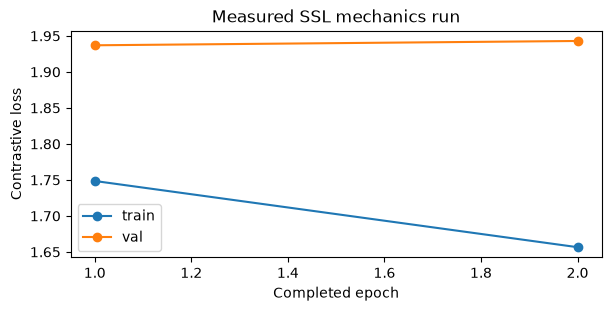

{'parameter': 'conv1.weight',
 'expected_update': True,
 'delta_l2': 0.025149405002593994,
 'before_sha256': 'd528e18dac221a3437f5041e200d5f1a039bb5ccebe5e3951ba1afe154ac16a6',
 'after_sha256': 'dae748d67b288c2ab5745adf81cd91f44ecdf6c4574c6d6fdbf96c87629bef26',
 'scope': 'one actual encoder parameter, not only the classifier head'}

In [2]:
ssl_result = run_learning_recipe(PROJECT, 'simclr_wsi', SPLIT_MANIFEST, OUT / 'simclr', device=DEVICE)
assert ssl_result['training']['optimizer_steps_this_run'] == 6
assert ssl_result['training']['data_contract']['labels_used'] is False
assert ssl_result['encoder_update']['delta_l2'] > 0
history = pd.DataFrame(ssl_result['history'])
fig, ax = plt.subplots(figsize=(6, 3), layout='constrained')
for split in ('train', 'val'):
    ax.plot(history['epoch'], history[f'{split}/loss'], marker='o', label=split)
ax.set(xlabel='Completed epoch', ylabel='Contrastive loss', title='Measured SSL mechanics run')
ax.legend()
fig.savefig(OUT / 'ssl_curve.png')
plt.show()
display(ssl_result['encoder_update'])


## 3. Fine-tuning: update pretrained encoder weights using slide labels

Fine-tune ImageNet DINO ViT-S/16 and ImageNet ResNet-50. Also continue from the small local SSL ResNet to make the **pretrain → fine-tune** sequence explicit. All use the same two-patch slide mini-bags, mean pooling, diagnosis labels, step budget and optimizer settings.

Encoder parameters receive gradients here. The recorded parameter-change witness distinguishes this from the frozen-encoder head training in the main notebook.

Recipes: `finetune_dino`, `finetune_resnet50` and `finetune_local_ssl`. The local SSL transfer loads only encoder weights into a fresh supervised model and verifies the source checkpoint checksum.

In [3]:
results = []
for experiment in ('finetune_dino', 'finetune_resnet50'):
    results.append(run_learning_recipe(PROJECT, experiment, SPLIT_MANIFEST, OUT / experiment, device=DEVICE))
ssl_checkpoint = Path(ssl_result['training']['checkpoint']).resolve(strict=True)
results.append(run_learning_recipe(PROJECT, 'finetune_local_ssl', SPLIT_MANIFEST, OUT / 'finetune_local_ssl',
    device=DEVICE, overrides=[f'model.net.encoder.source_checkpoint={json.dumps(str(ssl_checkpoint))}',
                             f'model.net.encoder.source_checkpoint_sha256={sha256(ssl_checkpoint)}']))
assert all(r['encoder_update']['delta_l2'] > 0 for r in results)


Seed set to 42


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..


`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..


... (16 outputs left out)

`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..


`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..


`Trainer(limit_test_batches=1.0)` was configured so 100% of the batches will be used..


`Trainer.fit` stopped: `max_epochs=2` reached.


## 4. From scratch: change initialization, keep the supervised task

Create the same ViT-S/16 and ResNet-50 architectures with random weights. Use the same data, update budget and learning rate as their pretrained counterparts. These short runs illustrate initialization; they cannot fairly rank fully trained models, and scratch training generally needs a separately justified optimization budget.

Recipes: `scratch_vit` and `scratch_resnet50`. They inherit the corresponding fine-tuning configuration and change pretrained initialization to `false`.

In [4]:
for experiment in ('scratch_vit', 'scratch_resnet50'):
    results.append(run_learning_recipe(PROJECT, experiment, SPLIT_MANIFEST, OUT / experiment, device=DEVICE))
assert all(r['test_evaluated'] is False and r['training']['optimizer_steps_this_run'] == 12 for r in results)


Seed set to 42


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..


`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..


... (6 outputs left out)

`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..


`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..


`Trainer(limit_test_batches=1.0)` was configured so 100% of the batches will be used..


`Trainer.fit` stopped: `max_epochs=2` reached.


## 5. Read measured changes, with their limits

Lightning records training loss averaged during each epoch and validation loss at the end of that epoch. Two validation slides yield coarse, unstable accuracy. Contrastive and cross-entropy losses have different objectives and scales; do not compare their values directly. Each recipe retains its best validation checkpoint, resolved configuration and encoder-update audit. Test evaluation remains disabled.

These runs establish that the recipes execute and encoder parameters learn. They do not establish useful self-supervised representations or which initialization performs best after adequate training.

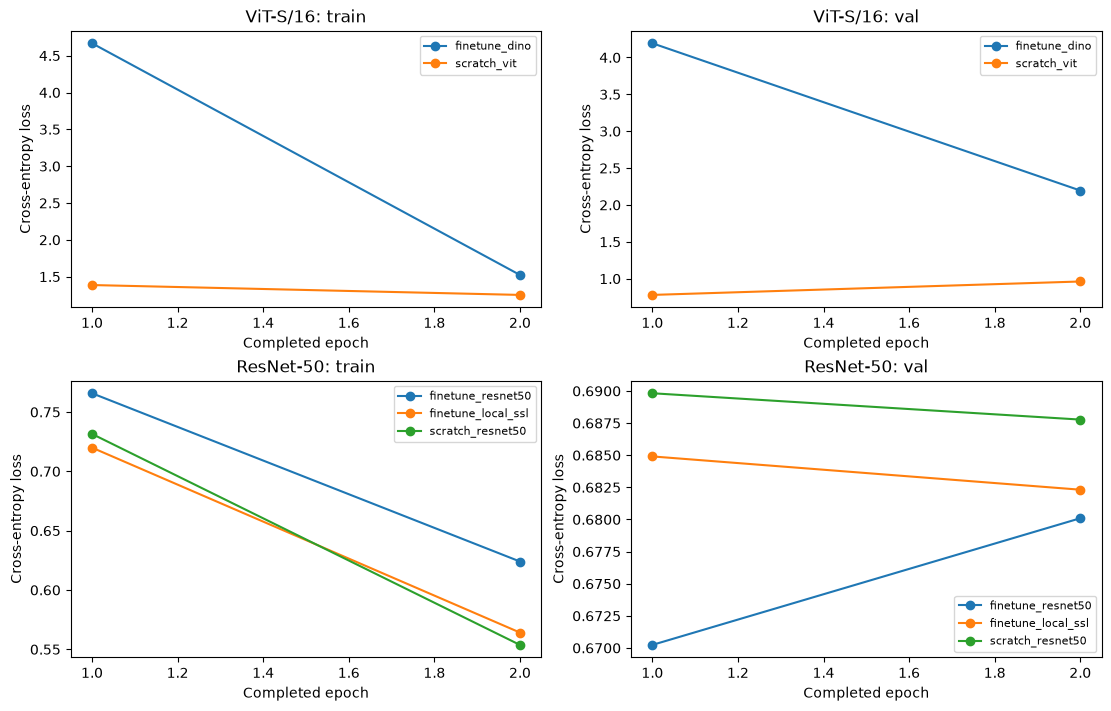

,recipe,encoder_update_l2,updates,final_train_loss,final_val_loss
0,finetune_dino,0.000640,12,1.523459,2.195574
1,finetune_resnet50,0.004276,12,0.624016,0.680096
2,finetune_local_ssl,0.003618,12,0.564132,0.682318
3,scratch_vit,0.000536,12,1.252406,0.961950
4,scratch_resnet50,0.003424,12,0.553720,0.687774


Outputs: /private/tmp/wsi-model-comparison/validation_representation3/runs/run_0dsgbkov


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout='constrained')
for result in results:
    experiment = result['experiment']
    row = 0 if experiment in ('finetune_dino', 'scratch_vit') else 1
    h = pd.DataFrame(result['history'])
    for column, split in enumerate(('train', 'val')):
        axes[row, column].plot(h['epoch'], h[f'{split}/loss'], marker='o', label=experiment)
        axes[row, column].set(title=f"{'ViT-S/16' if row == 0 else 'ResNet-50'}: {split}",
                             xlabel='Completed epoch', ylabel='Cross-entropy loss')
        axes[row, column].legend(fontsize=8)
fig.savefig(OUT / 'initialization_and_finetuning.png')
plt.show()
display(pd.DataFrame([{'recipe': r['experiment'], 'encoder_update_l2': r['encoder_update']['delta_l2'],
    'updates': r['training']['optimizer_steps_this_run'],
    'final_train_loss': r['history'][-1]['train/loss'], 'final_val_loss': r['history'][-1]['val/loss']} for r in results]))
receipt = {'status': 'complete', 'scope': 'bounded real-data Lightning/Hydra learning mechanics',
    'split_manifest': str(SPLIT_MANIFEST), 'split_sha256': sha256(SPLIT_MANIFEST),
    'test_pixels_read': False, 'ssl': ssl_result, 'supervised': results,
    'source_sha256': source_hashes(PROJECT)}
(OUT / 'run_receipt.json').write_text(json.dumps(receipt, indent=2, allow_nan=False))
print('Outputs:', OUT)


## Original references

- **SimCLR:** Chen et al. (ICML 2020), [A Simple Framework for Contrastive Learning of Visual Representations](https://arxiv.org/abs/2002.05709). Contrastive learning with augmented positive pairs and a projection head. The small executable SSL example above is inspired by this objective.
- **DINO:** Caron et al. (ICCV 2021), [Emerging Properties in Self-Supervised Vision Transformers](https://arxiv.org/abs/2104.14294). Teacher–student self-distillation without labels, using a momentum teacher and multiple views. We use published DINO weights; we do not reproduce DINO pretraining here.
- **BYOL:** Grill et al. (NeurIPS 2020), [Bootstrap Your Own Latent: A New Approach to Self-Supervised Learning](https://arxiv.org/abs/2006.07733). An online network predicts a moving-average target representation without explicit negative pairs. Included as a conceptual alternative, not implemented in this notebook.


## Model initialization and training data

| Initialization used here | Prior training strategy | Prior training data and use in this notebook |
| --- | --- | --- |
| **DINO ViT-S/16** (`timm/vit_small_patch16_224.dino`) | Self-supervised multi-crop teacher/student distillation without class labels. | **ImageNet-1k** images; this notebook then fine-tunes encoder and slide head on the declared TCGA training patients. [Model card](https://huggingface.co/timm/vit_small_patch16_224.dino), [paper](https://arxiv.org/abs/2104.14294). |
| **ResNet-50 IMAGENET1K_V2** (`resnet50-11ad3fa6.pth`) | Supervised 1,000-class classification using TorchVision's improved recipe. | **ImageNet-1k**; then supervised fine-tuning on the same TCGA training split. [Official weights](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet50.html). |
| **Local SSL ResNet-50** | Random initialization, followed by the small SimCLR-style two-view contrastive run in this notebook; no diagnosis labels in SSL. | External pretraining data: **none**. The local SSL checkpoint uses two sampled patches per TCGA training slide, then supplies encoder weights for supervised fine-tuning on those training patients. |
| **Random ViT-S/16 and ResNet-50** | No pretraining; supervised encoder/slide-head training from random weights. | Pretraining data: **none**. Training uses the same declared TCGA training patients and bounded patch subset. |

Validation selects checkpoints; validation/test labels do not enter optimization, and test-slide pixels are not read here. These two-epoch recipes demonstrate initialization and parameter updates, not useful representation quality or generalization. UNI is not run in this training notebook; its frozen-encoder provenance is documented in the classification demo.
